In [1]:
import copy
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (balanced_accuracy_score, accuracy_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

FEATS = "features.npy"                     # кадровые признаки ResNet18: (272, 16, 512)
df = pd.read_csv("index.csv")
feats = np.load(FEATS)
print(FEATS, feats.shape)
device = "cuda" if torch.cuda.is_available() else "cpu"

def part(split):
    m = (df.split == split).values
    return feats[m], df.label.values[m]

X_tr, y_tr = part("train")
X_va, y_va = part("val")
X_te, y_te = part("test")

# стандартизация по статистике train (как StandardScaler у SVM)
mu, sd = X_tr.mean(axis=(0, 1)), X_tr.std(axis=(0, 1)) + 1e-6
to_t = lambda X: torch.tensor((X - mu) / sd, dtype=torch.float32)
X_tr, X_va, X_te = to_t(X_tr), to_t(X_va), to_t(X_te)
y_tr_t = torch.tensor(y_tr)

features.npy (272, 16, 512)


In [2]:
class LSTMClassifier(nn.Module):
    def __init__(self, in_dim=512, hidden=128, n_classes=2, dropout=0.5):
        super().__init__()
        self.lstm = nn.LSTM(in_dim, hidden, batch_first=True)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden, n_classes)

    def forward(self, x):            # x: (batch, 16, 512)
        _, (h, _) = self.lstm(x)     # h: скрытое состояние после последнего кадра
        return self.fc(self.drop(h[-1]))

In [3]:
counts = np.bincount(y_tr)
class_w = torch.tensor(counts.sum() / (2 * counts), dtype=torch.float32, device=device)

def predict(model, X):
    model.eval()
    with torch.no_grad():
        return model(X.to(device)).cpu()

def train_once(seed, epochs=100, lr=1e-3, wd=1e-4):
    torch.manual_seed(seed)
    model = LSTMClassifier().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    crit = nn.CrossEntropyLoss(weight=class_w)
    dl = DataLoader(TensorDataset(X_tr, y_tr_t), batch_size=32, shuffle=True)

    best_loss, best_state, hist = np.inf, None, []
    for ep in range(epochs):
        model.train()
        tl = 0
        for x, y in dl:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            loss = crit(model(x), y)
            loss.backward()
            opt.step()
            tl += loss.item() * len(y)

        out = predict(model, X_va)
        vl = crit(out.to(device), torch.tensor(y_va, device=device)).item()
        vb = balanced_accuracy_score(y_va, out.argmax(1))
        hist.append((tl / len(y_tr), vl, vb))

        if vl < best_loss:                       # early stopping по val loss
            best_loss, best_state = vl, copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    return model, np.array(hist)

model, hist = train_once(seed=0)

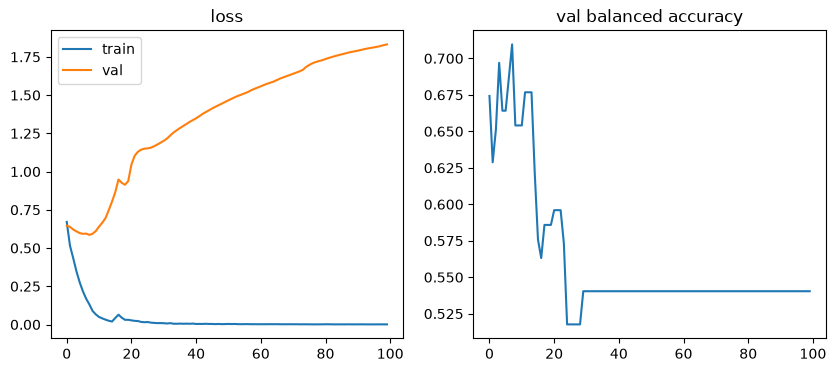

              precision    recall  f1-score   support

         eat       0.56      0.44      0.49        34
       drink       0.64      0.74      0.69        46

    accuracy                           0.61        80
   macro avg       0.60      0.59      0.59        80
weighted avg       0.60      0.61      0.60        80



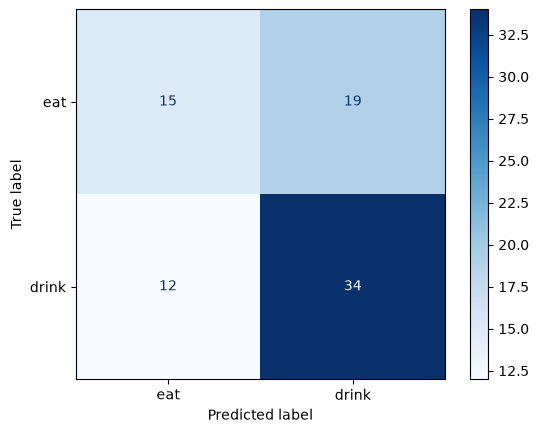

In [4]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4))
a1.plot(hist[:, 0], label="train"); a1.plot(hist[:, 1], label="val")
a1.set_title("loss"); a1.legend()
a2.plot(hist[:, 2]); a2.set_title("val balanced accuracy")
plt.show()

pred = predict(model, X_te).argmax(1).numpy()
print(classification_report(y_te, pred, target_names=["eat", "drink"]))
ConfusionMatrixDisplay.from_predictions(y_te, pred, display_labels=["eat", "drink"], cmap="Blues");

In [6]:
rows = []
for s in range(5):
    m, h = train_once(seed=s)
    p = predict(m, X_te).argmax(1).numpy()
    rows.append({"seed": s,
                 "best_epoch": int(h[:, 1].argmin()) + 1,   # эпоха с минимальным val loss
                 "test_acc": accuracy_score(y_te, p),
                 "test_bal_acc": balanced_accuracy_score(y_te, p),
                 "test_f1_macro": f1_score(y_te, p, average="macro")})

res = pd.DataFrame(rows)
print(res.round(3))
print(res.drop(columns=["seed", "best_epoch"]).agg(["mean", "std"]).round(3))
res.to_csv(f"results_lstm_{FEATS[:-4]}.csv", index=False)

   seed  best_epoch  test_acc  test_bal_acc  test_f1_macro
0     0           8     0.612         0.590          0.589
1     1           3     0.650         0.646          0.644
2     2           6     0.612         0.605          0.605
3     3           7     0.662         0.637          0.638
4     4           7     0.600         0.572          0.567
      test_acc  test_bal_acc  test_f1_macro
mean     0.628         0.610          0.609
std      0.027         0.031          0.032
